# Notebook 03 — Load-adaptive PI (B2), cooling-electricity accounting, and comparison with fixed-setpoint PI (B1)

Stage 3. Code: `src/controllers.py` (B1 `FixedSetpointPI`, B2 `LoadAdaptivePI`, simulator, energy accounting) on the plant from `src/thermal_model.py`.

<div style="background:#fff4e5;border-left:6px solid #eb6834;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Scope and claim discipline</b><br>
<ul><li>Two controllers that share <b>identical</b> PI law, gains, anti-windup and actuator limits. Only the setpoint rule differs.</li><li>Every number is a <b>model result with illustrative [ILL] parameters</b>. This is not a real-facility validation.</li><li>A saving is claimed <b>only</b> when both runs are complete, stay within the stated limits, settle, and return to their starting states within declared tolerances. Otherwise the comparison is reported as infeasible or inconclusive.</li><li>Overload and low-load scenarios (S3–S5) test failure behaviour only. They are never energy rankings.</li><li>No MPC, optimal control or gain retuning here.</li></ul>
</div>

<div style="background:#f1f1ef;border-left:6px solid #6b6b66;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>AI acknowledgement</b><br>
Drafted by Claude (Anthropic), used through Claude Code, at the team's request on 29 Oct 2026. The team must review it and be able to explain it. See <code>AI_USE_LOG.md</code>.
</div>

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..", "src").resolve()))
import thermal_model as tm
import controllers as ct

FIG_DIR = Path("..", "figures").resolve()
FIG_DIR.mkdir(exist_ok=True)
p = tm.Params()
H = 3600.0

# ---- declared tolerances and horizon (fixed before any comparison run) ----
HORIZON = 17 * H        # common horizon for every comparison run, s
FINE_DT = 5.0           # intersample inspection / quadrature grid, s
TOL_SETTLE = 0.1        # settling band around the controller's own setpoint, K
TOL_SAFETY = 1e-6       # numerical tolerance on the limits (air 18-27 C, equipment <= 40 C), K
TOL_TERMINAL = 1e-3     # |T(end) - T(start)| for both states, K
TOL_DU = 1e-4           # |dU| * max(1/COP) must be <= TOL_DU * E_cool  (electricity-equivalent bound)
T_A_BAND, T_S_MAX = (18.0, 27.0), 40.0

results, findings = [], []


def record(cid, desc, value, criterion, passed):
    results.append((cid, desc, value, criterion, bool(passed)))
    print(f"[{'PASS' if passed else 'FAIL'}] {cid}: {desc}\n        measured: {value}   criterion: {criterion}")
    assert passed, f"{cid} failed"


def finding(fid, text):
    findings.append((fid, text))
    print(f"[FINDING] {fid}: {text}")


print(f"numpy {np.__version__}, matplotlib {matplotlib.__version__}")
print(f"horizon {HORIZON/H:.0f} h; inspection grid {FINE_DT} s; settling band +/-{TOL_SETTLE} K; safety tolerance {TOL_SAFETY} K;")
print(f"terminal tolerance {TOL_TERMINAL} K; dU bound {TOL_DU:.0e} x E_cool; limits: air {T_A_BAND[0]}-{T_A_BAND[1]} C, equipment <= {T_S_MAX} C")

numpy 2.5.4, matplotlib 3.11.2
horizon 17 h; inspection grid 5.0 s; settling band +/-0.1 K; safety tolerance 1e-06 K;
terminal tolerance 0.001 K; dU bound 1e-04 x E_cool; limits: air 18.0-27.0 C, equipment <= 40.0 C


## 1. The two controllers

| | B1, fixed-setpoint PI (Stage 2) | B2, load-adaptive PI (new) |
|---|---|---|
| Setpoint | constant 24 °C | at each update, from the **current measured load**: $T_{set}=\mathrm{clip}\big(\min(27,\ 40-P_{IT}/UA_s)-1,\ 18,\ 27\big)$ °C |
| PI law, update order, sign, $Q_{ff}=0$, anti-windup, $0\le Q_c\le Q_{\max}$ | Stage 2 | **identical** |
| Gains | stored Stage 2 values per update interval | **identical** (no retuning) |

**Why this rule?**

- At steady state the equipment runs $P_{IT}/UA_s$ kelvin above the air (spec Prop. 5).
- So the warmest air that keeps the lumped equipment at or below the **illustrative** 40 °C limit is $40-P_{IT}/UA_s$, capped at 27 °C.
- Subtract a **provisional** 1 K margin.

At 1.0 MW this gives the same 24 °C as B1. At lower load it allows up to 26 °C.

**Caveats:**

- The margin is not a safety guarantee.
- In overload the clip only bounds the setpoint; it cannot make temperatures safe.
- Because B2 *measures* load, a load step changes its setpoint at that same update. This acts like an immediate load feedforward that B1 does not have, so it affects transients as well as steady-state energy.

In [2]:
for cid, P, expect in (("SP1", 0.6e6, 26.0), ("SP2", 1.0e6, 24.0), ("SP3", 1.7e6, 18.0), ("SP4", 0.8e6, 26.0)):
    raw = min(27.0, 40.0 - P / p.UA_s) - 1.0
    sp = ct.adaptive_setpoint(P, p.UA_s)
    record(cid, f"B2 setpoint at {P/1e6:.1f} MW", f"raw {raw:.2f} C -> clipped {sp:.2f} C", f"{expect:.2f} C",
           np.isclose(sp, expect, atol=1e-12))
print("At 1.7 MW the raw value 13.5 C is clipped to 18 C; this bounds the setpoint only, not the temperatures.")

for dt, g in ct.STAGE2_GAINS.items():
    g_re, _ = ct.design_gains(p, float(dt), ct.STAGE2_KP_GRID, ct.STAGE2_KI_GRID, gain_margin=2.0)
    record(f"G0-{dt}", f"stored Stage 2 gains at dt={dt}s are reproduced exactly by the Stage 2 design rule",
           f"Kp {g.Kp!r}, Ki {g.Ki!r}", "bit-identical", g_re.Kp == g.Kp and g_re.Ki == g.Ki)
    record(f"G1-{dt}", f"dt={dt}s: unsaturated closed-loop poles inside unit circle (setpoint does not enter M)",
           f"rho = {ct.spectral_radius(p, g):.4f}", "< 1", ct.spectral_radius(p, g) < 1)

[PASS] SP1: B2 setpoint at 0.6 MW
        measured: raw 26.00 C -> clipped 26.00 C   criterion: 26.00 C
[PASS] SP2: B2 setpoint at 1.0 MW
        measured: raw 24.00 C -> clipped 24.00 C   criterion: 24.00 C
[PASS] SP3: B2 setpoint at 1.7 MW
        measured: raw 13.50 C -> clipped 18.00 C   criterion: 18.00 C
[PASS] SP4: B2 setpoint at 0.8 MW
        measured: raw 26.00 C -> clipped 26.00 C   criterion: 26.00 C
At 1.7 MW the raw value 13.5 C is clipped to 18 C; this bounds the setpoint only, not the temperatures.


[PASS] G0-60: stored Stage 2 gains at dt=60s are reproduced exactly by the Stage 2 design rule
        measured: Kp 8096.1359720760265, Ki 630.9573444801937   criterion: bit-identical
[PASS] G1-60: dt=60s: unsaturated closed-loop poles inside unit circle (setpoint does not enter M)
        measured: rho = 0.6862   criterion: < 1


[PASS] G0-300: stored Stage 2 gains at dt=300s are reproduced exactly by the Stage 2 design rule
        measured: Kp 0.0, Ki 199.52623149688807   criterion: bit-identical
[PASS] G1-300: dt=300s: unsaturated closed-loop poles inside unit circle (setpoint does not enter M)
        measured: rho = 0.5649   criterion: < 1


## 2. Prediction from the COP slope, made **before** any simulation

At quasi-steady state with air temperature $\bar T$, the cooling needed is $Q=P_{IT}+UA_e(T_{out}-\bar T)$, and the cooling electricity is $Q/\mathrm{COP}(\bar T,T_{out})$.

B2 differs from B1 only while the load is below 1 MW. There its setpoint is **26 °C instead of 24 °C**: 2 K warmer.

**Prediction method:**

- integrate the quasi-steady electricity over each scenario's constant pieces;
- ignore transients (they are short) and stored-heat changes (they cancel over a closed cycle).

This is an estimate to compare against, not a result.

In [3]:
for To in (30.0, 35.0):
    c24, c26 = tm.cop(p, 24.0, To), tm.cop(p, 26.0, To)
    print(f"T_out {To:.0f} C: COP(24 C) = {c24:.3f}, COP(26 C) = {c26:.3f}; slope ~ {(c26-c24)/2:.3f} per K "
          f"({100*((c26/c24)**0.5-1):.2f} % per K); electricity per joule removed falls by {100*(1-c24/c26):.2f} %")

# constant pieces: (duration in h, P_IT in W, T_out in C)
PIECES = {
    "S1":  [(1.0, 0.6e6, 30.0), (8.0, 1.0e6, 30.0), (8.0, 0.6e6, 30.0)],
    "S2c": [(1.0, 0.8e6, 30.0), (8.0, 0.8e6, 35.0), (8.0, 0.8e6, 30.0)],
}


def predicted_kWh(pieces, setpoint_rule):
    E = 0.0
    for hours, P, To in pieces:
        Ts = setpoint_rule(P)
        E += (P + p.UA_e * (To - Ts)) / tm.cop(p, Ts, To) * hours
    return E / 1e3


PRED = {}
for sid, pieces in PIECES.items():
    e1 = predicted_kWh(pieces, lambda P: 24.0)
    e2 = predicted_kWh(pieces, lambda P: ct.adaptive_setpoint(P, p.UA_s))
    PRED[sid] = (e1, e2, (e1 - e2) / e1)
    print(f"PREDICTION {sid}: B1 {e1:.1f} kWh_e, B2 {e2:.1f} kWh_e, predicted signed saving {100*PRED[sid][2]:+.2f} %")

T_out 30 C: COP(24 C) = 4.935, COP(26 C) = 5.384; slope ~ 0.224 per K (4.45 % per K); electricity per joule removed falls by 8.34 %
T_out 35 C: COP(24 C) = 4.139, COP(26 C) = 4.456; slope ~ 0.158 per K (3.75 % per K); electricity per joule removed falls by 7.10 %
PREDICTION S1: B1 2756.5 kWh_e, B2 2656.8 kWh_e, predicted signed saving +3.62 %
PREDICTION S2c: B1 3069.4 kWh_e, B2 2819.3 kWh_e, predicted signed saving +8.15 %


## 3. Cooling-electricity accounting
<div style="background:#e7f7f0;border-left:6px solid #1baf7a;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Algorithm (inside the simulator)</b><br>
On every fine segment $[a,b]$ (5 s, also split at updates and disturbance changes), $Q_c$ and $T_{out}$ are constant and $T_a(t)$ is smooth. The segment contributes $Q_c\,\frac{b-a}{6}\big(g(a)+4g(m)+g(b)\big)$ with $g=1/\mathrm{COP}(T_a,T_{out})$ (Simpson's rule). The midpoint state $m$ is propagated <b>exactly</b> with a half-step matrix exponential. COP is evaluated only where $Q_c>0$; if it leaves its domain, the run is stopped and labelled. The stopped segment's electricity is not added.
</div>

**Quantities reported:**

| Symbol | Meaning | Unit |
|---|---|---|
| $E_{cool}=\int Q_c/\mathrm{COP}\,dt$ | cooling electricity | kWh$_e$ |
| $E_Q=\int Q_c\,dt$ | heat removed | kWh$_{th}$ |
| $E_{IT}$ | IT electricity | kWh$_e$ |
| $E_{cool}/E_{IT}$ | cooling-to-IT electricity ratio | – |
| $\max Q_c/\mathrm{COP}$ | peak cooling power | kW$_e$ |
| $\Delta U=C_s\,\Delta T_s+C_a\,\Delta T_a$ | stored heat gained over the run | J and kWh$_{th}$ |

**Not included:** constant fan electricity, which would add the same amount to both controllers. kWh$_e$ and kWh$_{th}$ are never added together.

## 4. Fair-comparison protocol

**Scenarios.** Closed cycles in which *both* load and outdoor temperature return to their starting values:

| ID | Disturbance | Note |
|---|---|---|
| S1 | load 0.6 → 1.0 MW at 1 h → 0.6 MW at 9 h; $T_{out}=30$ °C | same as Stage 2; already a closed cycle |
| **S2c** | load 0.8 MW; $T_{out}$ 30 → 35 °C at 1 h → **30 °C at 9 h** | **new comparison variant** of Stage 2's S2, with an added return leg. Stage 2's S2 itself is unchanged |

**Common to all runs:**

- the same disturbance traces;
- the same horizon (17 h, i.e. 8 h after the last change), so all recovery energy is included;
- the same 5 s inspection grid and the same tolerances (printed at the top).

**Initial states differ, and this is disclosed.** Each controller starts bumpless at **its own** equilibrium at the starting load:

- B1 at $T_a=24$ °C;
- B2 at its setpoint, 26 °C at 0.6 MW and 0.8 MW.

Each must return to that same state by the end (terminal check). $\Delta U/\overline{\mathrm{COP}}$ is **not** used as a correction.

**Eligibility for a savings claim:** *both* runs must

1. complete (no COP-domain stop);
2. stay within air 18–27 °C and equipment ≤ 40 °C, beyond the numerical tolerance nowhere on the 5 s grid, after upward *and* downward changes;
3. settle within ±0.1 K of their own setpoint before the next change and before the end;
4. return to their start state (|ΔT| ≤ 1e-3 K) with $|\Delta U|\cdot\max g \le 10^{-4}E_{cool}$.

Signed saving $=(E_{B1}-E_{B2})/E_{B1}$. A negative value or zero is a valid outcome.

In [4]:
PD = ct.PiecewiseDisturbance
CMP = {
    "S1":  dict(dist=PD([0, 1*H, 9*H], [0.6e6, 1.0e6, 0.6e6], [30.0, 30.0, 30.0]),
                events=[(1*H, 9*H, "load up 0.6->1.0 MW"), (9*H, HORIZON, "load down 1.0->0.6 MW")]),
    "S2c": dict(dist=PD([0, 1*H, 9*H], [0.8e6, 0.8e6, 0.8e6], [30.0, 35.0, 30.0]),
                events=[(1*H, 9*H, "T_out up 30->35 C"), (9*H, HORIZON, "T_out down 35->30 C")]),
}


def make_ctrl(kind, dt, P0):
    g = ct.STAGE2_GAINS[dt]
    if kind == "B1":
        return ct.FixedSetpointPI(g, 24.0, Q_min=0.0, Q_max=p.Q_max)
    return ct.LoadAdaptivePI(g, ct.adaptive_setpoint(P0, p.UA_s), Q_min=0.0, Q_max=p.Q_max, UA_s=p.UA_s)


def run(kind, dt, dist, t_end=HORIZON, fine_dt=FINE_DT, aw=True):
    P0, To0 = dist.at(0.0)
    ctrl = make_ctrl(kind, dt, P0)
    ctrl.anti_windup = aw
    Q0 = tm.holding_cooling(p, ctrl.T_set, P0, To0)
    x0 = tm.equilibrium(p, Q0, P0, To0)
    ctrl.initialize(Q0)
    res = ct.simulate_closed_loop(p, ctrl, dist, x0, t_end, fine_dt=fine_dt)
    res.meta["x0"], res.meta["Q0"] = x0, Q0
    return res


R = {}
for sid, s in CMP.items():
    for dt in (60, 300):
        for kind in ("B1", "B2"):
            R[(sid, dt, kind)] = run(kind, dt, s["dist"])
for sid in CMP:
    for kind in ("B1", "B2"):
        r = R[(sid, 60, kind)]
        print(f"{sid} {kind}: starts at its own equilibrium T_s = {r.meta['x0'][0]:.2f} C, T_a = {r.meta['x0'][1]:.2f} C, "
              f"Q_c = {r.meta['Q0']/1e6:.4f} MW_th, setpoint {r.SP[0]:.2f} C")
print("status:", {f"{k[0]}/{k[1]}s/{k[2]}": v.status for k, v in R.items()})

S1 B1: starts at its own equilibrium T_s = 33.00 C, T_a = 24.00 C, Q_c = 0.6120 MW_th, setpoint 24.00 C
S1 B2: starts at its own equilibrium T_s = 35.00 C, T_a = 26.00 C, Q_c = 0.6080 MW_th, setpoint 26.00 C
S2c B1: starts at its own equilibrium T_s = 36.00 C, T_a = 24.00 C, Q_c = 0.8120 MW_th, setpoint 24.00 C
S2c B2: starts at its own equilibrium T_s = 38.00 C, T_a = 26.00 C, Q_c = 0.8080 MW_th, setpoint 26.00 C
status: {'S1/60s/B1': 'completed', 'S1/60s/B2': 'completed', 'S1/300s/B1': 'completed', 'S1/300s/B2': 'completed', 'S2c/60s/B1': 'completed', 'S2c/60s/B2': 'completed', 'S2c/300s/B1': 'completed', 'S2c/300s/B2': 'completed'}


## 5. Verification

| ID | Check |
|---|---|
| EQ | B2's starting point is a true equilibrium, and with no disturbance B2 stays there (both intervals) |
| R | Independent `solve_ivp` replay of every comparison run, restarted at updates and disturbance changes |
| E | Thermal energy balance $E_Q=E_{IT}+E_{env}-\Delta U$, and heat removed = $\sum Q_c h$ |
| G | Intersample extrema and $E_{cool}$ on the 5 s grid vs a 1 s grid |
| Q | Cooling electricity re-computed **independently**: re-propagate with `simulate_zoh` on a 0.5 s grid, then apply trapezoid quadrature |
| AW | Anti-windup invariant (limited integration ⇒ $Q_c$ at a limit) on every B2 run |
| T | Terminal state and $\Delta U$ (feeds eligibility) |

In [5]:
for dt in (60, 300):
    P0, To0 = 0.6e6, 30.0
    c = make_ctrl("B2", dt, P0)
    Q0 = tm.holding_cooling(p, c.T_set, P0, To0)
    x0 = tm.equilibrium(p, Q0, P0, To0)
    A, _, _, G = tm.system_matrices(p)
    resid = np.max(np.abs(A @ x0 + G @ np.array([Q0, P0, To0])))
    c.initialize(Q0)
    r0 = ct.simulate_closed_loop(p, c, PD([0.0], [P0], [To0]), x0, 6 * H)
    drift, dQ = np.max(np.abs(r0.X[:, :2] - x0)), np.max(np.abs(r0.log["u"] - Q0)) / Q0
    record(f"EQ-{dt}", f"dt={dt}s: B2 equilibrium at 0.6 MW (T_a = {x0[1]:.2f} C, T_s = {x0[0]:.2f} C) is stationary; "
           f"no-disturbance run stays for 6 h", f"residual {resid:.1e} K/s, drift {drift:.1e} K, dQ/Q0 {dQ:.1e}",
           "< 1e-15 K/s, < 1e-8 K, < 1e-9", resid < 1e-15 and drift < 1e-8 and dQ < 1e-9)

for key, res in R.items():
    sid, dt, kind = key
    bks = np.unique(np.concatenate([res.log["t"], CMP[sid]["dist"].times, [res.t[-1]]]))
    idx = np.searchsorted(res.t, bks)
    W = np.column_stack([res.Q[idx[:-1]], res.P_IT[idx[:-1]], res.T_out[idx[:-1]]])
    Xr = tm.simulate_ivp(p, res.meta["x0"], bks, W)
    dT = np.max(np.abs(Xr[:, :2] - res.X[idx, :2]))
    record(f"R-{sid}-{dt}-{kind}", f"{sid} dt={dt}s {kind}: closed loop vs independent solve_ivp replay", f"{dT:.1e} K", "< 1e-6 K", dT < 1e-6)

for key, res in R.items():
    sid, dt, kind = key
    rel = abs(tm.energy_balance_residual(p, res.X)) / res.X[-1, 3]
    sumQh = np.sum(res.Q[:-1] * np.diff(res.t))
    relQ = abs(sumQh - (res.X[-1, 2] - res.X[0, 2])) / res.X[-1, 2]
    record(f"E-{sid}-{dt}-{kind}", f"{sid} dt={dt}s {kind}: thermal energy balance; heat removed = sum(Q_c h)",
           f"balance {rel:.1e}, E_Q {relQ:.1e}", "< 1e-9, < 1e-9", rel < 1e-9 and relQ < 1e-9)

for sid in CMP:
    for dt in (60, 300):
        r5 = R[(sid, dt, "B2")]
        r1 = run("B2", dt, CMP[sid]["dist"], fine_dt=1.0)
        d_ext = max(abs(r1.X[:, 1].max() - r5.X[:, 1].max()), abs(r1.X[:, 1].min() - r5.X[:, 1].min()),
                    abs(r1.X[:, 0].max() - r5.X[:, 0].max()))
        d_E = abs(r1.E_cool[-1] - r5.E_cool[-1]) / r1.E_cool[-1]
        record(f"G-{sid}-{dt}", f"{sid} dt={dt}s B2: 5 s vs 1 s grid: extrema; Simpson E_cool",
               f"extrema {d_ext:.1e} K, E_cool rel {d_E:.1e}", "< 0.01 K, < 1e-6", d_ext < 0.01 and d_E < 1e-6)


def independent_E_cool(res, dist, h=0.5):
    # re-propagate with Stage 1's simulate_zoh using only logged commands + disturbances, then trapezoid
    t_end = res.t[-1]
    grid = np.unique(np.concatenate([np.arange(0.0, t_end, h), res.log["t"], dist.times[dist.times < t_end], [t_end]]))
    k = np.searchsorted(res.log["t"], grid[:-1], side="right") - 1
    Q = res.log["u"][k]
    PT = np.array([dist.at(t) for t in grid[:-1]])
    X = tm.simulate_zoh(p, res.meta["x0"], grid, np.column_stack([Q, PT[:, 0], PT[:, 1]]))
    on = Q > 0
    gl = np.zeros_like(Q); gr = np.zeros_like(Q)
    gl[on] = 1.0 / tm.cop(p, X[:-1, 1][on], PT[on, 1])
    gr[on] = 1.0 / tm.cop(p, X[1:, 1][on], PT[on, 1])
    return np.sum(Q * np.diff(grid) * 0.5 * (gl + gr))


for key, res in R.items():
    sid, dt, kind = key
    E_ind = independent_E_cool(res, CMP[sid]["dist"])
    rel = abs(E_ind - res.E_cool[-1]) / res.E_cool[-1]
    record(f"Q-{sid}-{dt}-{kind}", f"{sid} dt={dt}s {kind}: Simpson (simulator) vs independent 0.5 s trapezoid",
           f"rel diff {rel:.1e}", "< 1e-5", rel < 1e-5)

[PASS] EQ-60: dt=60s: B2 equilibrium at 0.6 MW (T_a = 26.00 C, T_s = 35.00 C) is stationary; no-disturbance run stays for 6 h
        measured: residual 5.6e-17 K/s, drift 3.5e-10 K, dQ/Q0 3.8e-11   criterion: < 1e-15 K/s, < 1e-8 K, < 1e-9
[PASS] EQ-300: dt=300s: B2 equilibrium at 0.6 MW (T_a = 26.00 C, T_s = 35.00 C) is stationary; no-disturbance run stays for 6 h
        measured: residual 5.6e-17 K/s, drift 3.5e-10 K, dQ/Q0 3.8e-11   criterion: < 1e-15 K/s, < 1e-8 K, < 1e-9


[PASS] R-S1-60-B1: S1 dt=60s B1: closed loop vs independent solve_ivp replay
        measured: 3.9e-08 K   criterion: < 1e-6 K


[PASS] R-S1-60-B2: S1 dt=60s B2: closed loop vs independent solve_ivp replay
        measured: 3.4e-08 K   criterion: < 1e-6 K


[PASS] R-S1-300-B1: S1 dt=300s B1: closed loop vs independent solve_ivp replay
        measured: 3.9e-08 K   criterion: < 1e-6 K


[PASS] R-S1-300-B2: S1 dt=300s B2: closed loop vs independent solve_ivp replay
        measured: 3.4e-08 K   criterion: < 1e-6 K


...

[PASS] Q-S1-300-B2: S1 dt=300s B2: Simpson (simulator) vs independent 0.5 s trapezoid
        measured: rel diff 4.2e-08   criterion: < 1e-5


[PASS] Q-S2c-60-B1: S2c dt=60s B1: Simpson (simulator) vs independent 0.5 s trapezoid
        measured: rel diff 7.6e-08   criterion: < 1e-5


[PASS] Q-S2c-60-B2: S2c dt=60s B2: Simpson (simulator) vs independent 0.5 s trapezoid
        measured: rel diff 6.5e-08   criterion: < 1e-5


[PASS] Q-S2c-300-B1: S2c dt=300s B1: Simpson (simulator) vs independent 0.5 s trapezoid
        measured: rel diff 7.6e-08   criterion: < 1e-5


[PASS] Q-S2c-300-B2: S2c dt=300s B2: Simpson (simulator) vs independent 0.5 s trapezoid
        measured: rel diff 6.5e-08   criterion: < 1e-5


## 6. Failure-behaviour tests for B2 (never energy rankings)

These rerun the Stage 2 scenarios S3 (1.7 MW, above capacity), S4 (2.0 MW) and S5 (artificial idle with cool outdoor air) with B2, next to B1.

- Stopped runs are reported as stopped, with the logged COP-domain error.
- Their partial energies are **not** shown, because they are not complete-day energies.

In [6]:
FAIL = {
    "S3": PD([0, 1*H, 4830.0], [1.0e6, 1.7e6, 1.0e6], [30.0, 30.0, 30.0]),
    "S4": PD([0, 1*H, 2*H], [1.0e6, 2.0e6, 1.0e6], [30.0, 30.0, 30.0]),
    "S5": PD([0, 1*H, 5*H], [0.6e6, 0.0, 0.6e6], [30.0, 20.0, 30.0]),
}
FAIL_END = {"S3": 9*H, "S4": 9*H, "S5": 13*H}
RF = {}
FTXT = ["FAILURE-BEHAVIOUR TESTS (no energy ranking; illustrative parameters)",
        f"{'run':14s} {'status':28s} {'T_a range C':>15s} {'T_s max':>8s} {'Ta>27 h':>8s} {'Ta<18 h':>8s} {'Ts>40 h':>8s} "
        f"{'@Qmax min':>9s} {'@0 min':>7s} {'limited':>7s}"]
for sid, dist in FAIL.items():
    for dt in (60, 300):
        for kind in ("B1", "B2"):
            r = run(kind, dt, dist, t_end=FAIL_END[sid])
            RF[(sid, dt, kind)] = r
            v, s = ct.limit_violations(r, tol=TOL_SAFETY), ct.saturation_summary(r)
            st = "completed" if r.status == "completed" else f"STOPPED (COP) at {r.stop_time/H:.3f} h"
            FTXT.append(f"{sid} {dt:3d}s {kind:4s}  {st:28s} {v['T_a_min']:6.2f}..{v['T_a_max']:6.2f} {v['T_s_max']:8.2f} "
                        f"{v['T_a_above_max_h']:8.2f} {v['T_a_below_min_h']:8.2f} {v['T_s_above_max_h']:8.2f} "
                        f"{s['high_time']/60:9.0f} {s['low_time']/60:7.0f} {s['limited_updates']:7d}")
print("\n".join(FTXT))
for dt in (60, 300):
    r4 = RF[("S4", dt, "B2")]
    if r4.status == "stopped_cop_domain":
        record(f"COP-{dt}", f"dt={dt}s: B2 S4 stopped at the COP-domain violation and logged it",
               f"t = {r4.stop_time/H:.3f} h: {r4.message}", "stopped with message", bool(r4.message))
    else:
        finding(f"F-COP-{dt}", f"B2 S4 at dt={dt}s did not leave the COP domain")

for dt in (60, 300):
    n_lim = n_bad = 0
    for key, res in list(R.items()) + list(RF.items()):
        if key[1] == dt and key[2] == "B2":
            lg = res.log
            at_lim = np.isclose(lg["u"], p.Q_max, rtol=0, atol=1e-3) | np.isclose(lg["u"], 0.0, rtol=0, atol=1e-3)
            n_lim += int(lg["limited"].sum()); n_bad += int(np.sum(lg["limited"] & ~at_lim))
    record(f"AW-{dt}", f"dt={dt}s: anti-windup invariant on all B2 runs (comparison + failure tests)",
           f"{n_lim} limited updates, {n_bad} not at a limit", "0 not at a limit", n_bad == 0 and n_lim > 0)

FAILURE-BEHAVIOUR TESTS (no energy ranking; illustrative parameters)
run            status                           T_a range C  T_s max  Ta>27 h  Ta<18 h  Ts>40 h @Qmax min  @0 min limited
S3  60s B1    completed                     22.36.. 30.37    53.20     0.21     0.00     0.58        20       0      20
S3  60s B2    completed                     19.80.. 27.07    49.81     0.01     0.00     0.53        23       0      23
S3 300s B1    completed                     19.15.. 32.27    55.15     0.40     0.00     0.58        20       0       4
S3 300s B2    completed                     19.28.. 27.72    50.48     0.06     0.00     0.50        25       0       5
S4  60s B1    STOPPED (COP) at 1.265 h      24.00.. 36.60    60.20     0.20     0.00     0.26        11       0      11
S4  60s B2    STOPPED (COP) at 1.308 h      21.00.. 36.66    60.26     0.16     0.00     0.30        17       0      17
S4 300s B1    STOPPED (COP) at 1.240 h      24.00.. 36.67    60.27     0.20     0.00     

## 7. Results: energy and safety in one table (comparison runs)

In [7]:
def assess(res, sid):
    e, v = ct.energy_summary(p, res), ct.limit_violations(res, T_A_BAND, T_S_MAX, tol=TOL_SAFETY)
    on = res.Q[:-1] > 0
    g_max = np.nanmax(res.P_cool[:-1][on] / res.Q[:-1][on]) if on.any() else 0.0
    settle = [ct.event_metrics(res, a, b, tol=TOL_SETTLE)["settling_time"] for (a, b, _) in CMP[sid]["events"]]
    term_ok = (abs(e["dT_s_end_K"]) <= TOL_TERMINAL and abs(e["dT_a_end_K"]) <= TOL_TERMINAL
               and abs(e["dU_J"]) * g_max <= TOL_DU * res.E_cool[-1])
    return {"e": e, "v": v, "settle": settle, "settled": all(s is not None for s in settle), "term_ok": term_ok,
            "safe": v["within_limits"], "complete": e["complete"],
            "eligible_run": e["complete"] and v["within_limits"] and term_ok and all(s is not None for s in settle)}


A = {key: assess(res, key[0]) for key, res in R.items()}
hdr = (f"{'run':14s} {'E_cool':>8s} {'E_Q':>8s} {'E_IT':>8s} {'ratio':>6s} {'peak':>6s} {'T_a min..max':>13s} {'T_s max':>7s} "
       f"{'DH>27':>6s} {'DH<18':>6s} {'DH>40':>6s} {'maxViol':>7s} {'dU':>9s} {'settle (min)':>13s} {'term':>4s} {'feasible':>8s}")
units = (f"{'':14s} {'kWh_e':>8s} {'kWh_th':>8s} {'kWh_e':>8s} {'-':>6s} {'kW_e':>6s} {'C':>13s} {'C':>7s} "
         f"{'K h':>6s} {'K h':>6s} {'K h':>6s} {'K':>7s} {'J':>9s} {'up / down':>13s} {'':>4s} {'':>8s}")
TAB = ["RESULTS (model results, illustrative parameters; common 17 h horizon; checked on the 5 s grid)", hdr, units]
for key, a in A.items():
    e, v = a["e"], a["v"]
    mv = max(v["max_T_a_over"], v["max_T_a_under"], v["max_T_s_over"])
    st = " / ".join("n.s." if s is None else f"{s/60:.1f}" for s in a["settle"])
    TAB.append(f"{key[0]+' '+str(key[1])+'s '+key[2]:14s} {e['E_cool_kWh_e']:8.1f} {e['E_Q_kWh_th']:8.1f} {e['E_IT_kWh_e']:8.1f} "
               f"{e['cool_to_IT_ratio']:6.3f} {e['peak_P_cool_kW_e']:6.1f} {v['T_a_min']:6.2f}..{v['T_a_max']:5.2f} "
               f"{v['T_s_max']:7.2f} {v['T_a_above_max_Kh']:6.3f} {v['T_a_below_min_Kh']:6.3f} {v['T_s_above_max_Kh']:6.3f} "
               f"{mv:7.3f} {e['dU_J']:9.2e} {st:>13s} {'ok' if a['term_ok'] else 'FAIL':>4s} "
               f"{'yes' if a['eligible_run'] else 'NO':>8s}")
print("\n".join(TAB))
print("\nterminal-state errors (K):", {f"{k[0]}/{k[1]}/{k[2]}": (f"{a['e']['dT_s_end_K']:.1e}", f"{a['e']['dT_a_end_K']:.1e}") for k, a in A.items()})

# M: regression check for a metric bug found while building this notebook. SP[i] applies on [t_i, t_{i+1});
# at a window's end the NEXT setpoint is already in force, so an earlier version judged the last point of
# B2's window against the wrong setpoint and reported "not settled". The end point must use the setpoint
# in force during the window.
for dt in (60, 300):
    r = R[("S1", dt, "B2")]
    m_up = ct.event_metrics(r, 1 * H, 9 * H, tol=TOL_SETTLE)
    sp_end_next = r.SP[np.searchsorted(r.t, 9 * H)]
    record(f"M-{dt}", f"dt={dt}s: settling metric judges the window end against the in-force setpoint "
           f"(B2 S1 load-up window; setpoint at 9 h already {sp_end_next:.0f} C for the next window)",
           f"final error {m_up['final_err']:.1e} K, settling {m_up['settling_time']} s", f"|final error| <= {TOL_SETTLE} K, settled",
           abs(m_up["final_err"]) <= TOL_SETTLE and m_up["settling_time"] is not None)

for key, a in A.items():
    record(f"T-{key[0]}-{key[1]}-{key[2]}", f"{key[0]} dt={key[1]}s {key[2]}: returns to its start state; dU negligible",
           f"dT_s {a['e']['dT_s_end_K']:.1e} K, dT_a {a['e']['dT_a_end_K']:.1e} K, dU {a['e']['dU_J']:.2e} J",
           f"|dT| <= {TOL_TERMINAL} K, |dU| max g <= {TOL_DU:.0e} E_cool", a["term_ok"])

RESULTS (model results, illustrative parameters; common 17 h horizon; checked on the 5 s grid)
run              E_cool      E_Q     E_IT  ratio   peak  T_a min..max T_s max  DH>27  DH<18  DH>40 maxViol        dU  settle (min) term feasible
                  kWh_e   kWh_th    kWh_e      -   kW_e             C       C    K h    K h    K h       K         J     up / down              
S1 60s B1        2756.5  13604.0  13400.0  0.206  209.2  22.68..25.32   39.00  0.000  0.000  0.000   0.000  3.74e-02   15.5 / 15.5   ok      yes
S1 60s B2        2656.2  13568.0  13400.0  0.198  205.1  24.00..26.00   39.00  0.000  0.000  0.000   0.000  3.08e-02   13.3 / 13.3   ok      yes
S1 300s B1       2756.7  13604.0  13400.0  0.206  235.0  20.56..27.44   39.97  0.003  0.000  0.000   0.436  3.75e-02   31.7 / 31.7   ok       NO
S1 300s B2       2656.2  13568.0  13400.0  0.198  216.4  23.10..26.90   39.77  0.000  0.000  0.000   0.000  3.09e-02   30.7 / 30.7   ok      yes
S2c 60s B1       3069.4  13884.0  1

## 8. Comparison: eligibility, signed savings, and prediction vs measurement

In [8]:
CTXT = ["COMPARISON B1 (fixed 24 C) vs B2 (load-adaptive), signed saving = (E_B1 - E_B2) / E_B1",
        f"{'scenario':10s} {'dt':>4s} {'eligible':>9s} {'E_B1 kWh_e':>11s} {'E_B2 kWh_e':>11s} {'saving':>8s} {'predicted':>9s}  reason"]
for sid in CMP:
    for dt in (60, 300):
        a1, a2 = A[(sid, dt, "B1")], A[(sid, dt, "B2")]
        reasons = []
        for kind, a in (("B1", a1), ("B2", a2)):
            if not a["complete"]: reasons.append(f"{kind} stopped")
            if not a["safe"]:
                v = a["v"]
                reasons.append(f"{kind} outside limits (T_a max {v['T_a_max']:.2f} C, +{v['max_T_a_over']:.3f} K; "
                               f"T_a min {v['T_a_min']:.2f} C; T_s max {v['T_s_max']:.2f} C)")
            if not a["settled"]: reasons.append(f"{kind} not settled")
            if not a["term_ok"]: reasons.append(f"{kind} terminal check failed")
        ok = not reasons
        E1, E2 = a1["e"]["E_cool_kWh_e"], a2["e"]["E_cool_kWh_e"]
        sav = f"{100*(E1-E2)/E1:+.2f} %" if ok else "  n/a"
        CTXT.append(f"{sid:10s} {dt:4d} {'YES' if ok else 'NO':>9s} {E1:11.1f} {E2:11.1f} {sav:>8s} {100*PRED[sid][2]:+8.2f} %  "
                    f"{'both feasible, settled, terminal ok' if ok else '; '.join(reasons)}")
print("\n".join(CTXT))
print("\nNOTE: for non-eligible rows the energies are shown for transparency only; no saving is claimed from them.")

COMPARISON B1 (fixed 24 C) vs B2 (load-adaptive), signed saving = (E_B1 - E_B2) / E_B1
scenario     dt  eligible  E_B1 kWh_e  E_B2 kWh_e   saving predicted  reason
S1           60       YES      2756.5      2656.2  +3.64 %    +3.62 %  both feasible, settled, terminal ok
S1          300        NO      2756.7      2656.2      n/a    +3.62 %  B1 outside limits (T_a max 27.44 C, +0.436 K; T_a min 20.56 C; T_s max 39.97 C)
S2c          60       YES      3069.4      2819.3  +8.15 %    +8.15 %  both feasible, settled, terminal ok
S2c         300       YES      3069.4      2819.3  +8.15 %    +8.15 %  both feasible, settled, terminal ok

NOTE: for non-eligible rows the energies are shown for transparency only; no saving is claimed from them.


## 9. Figures

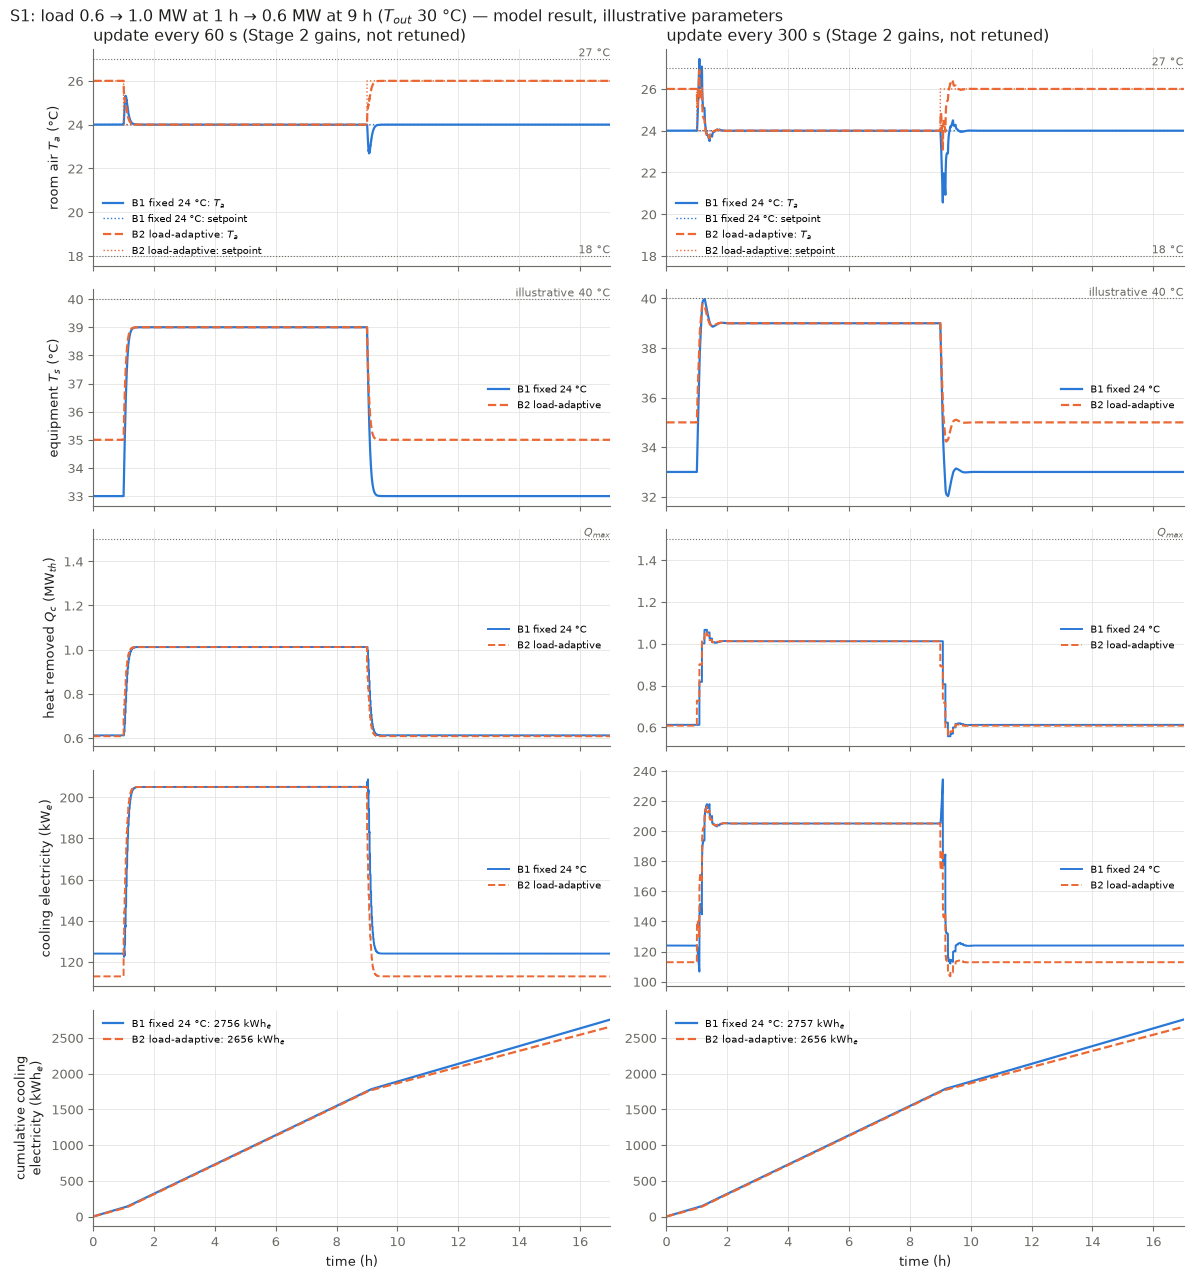

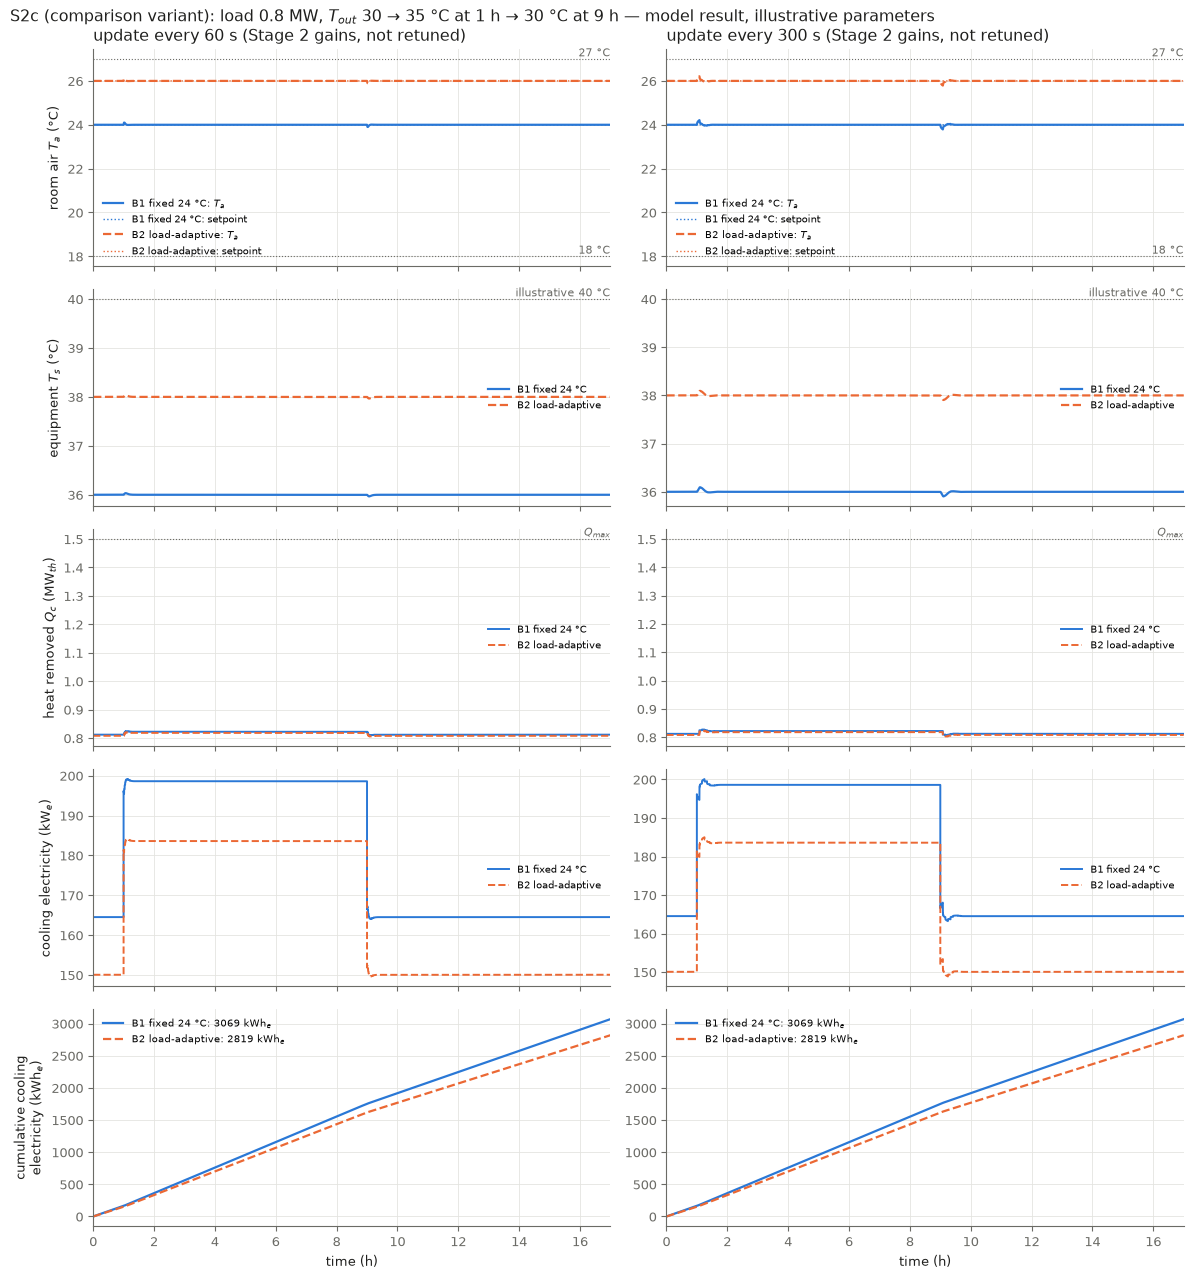

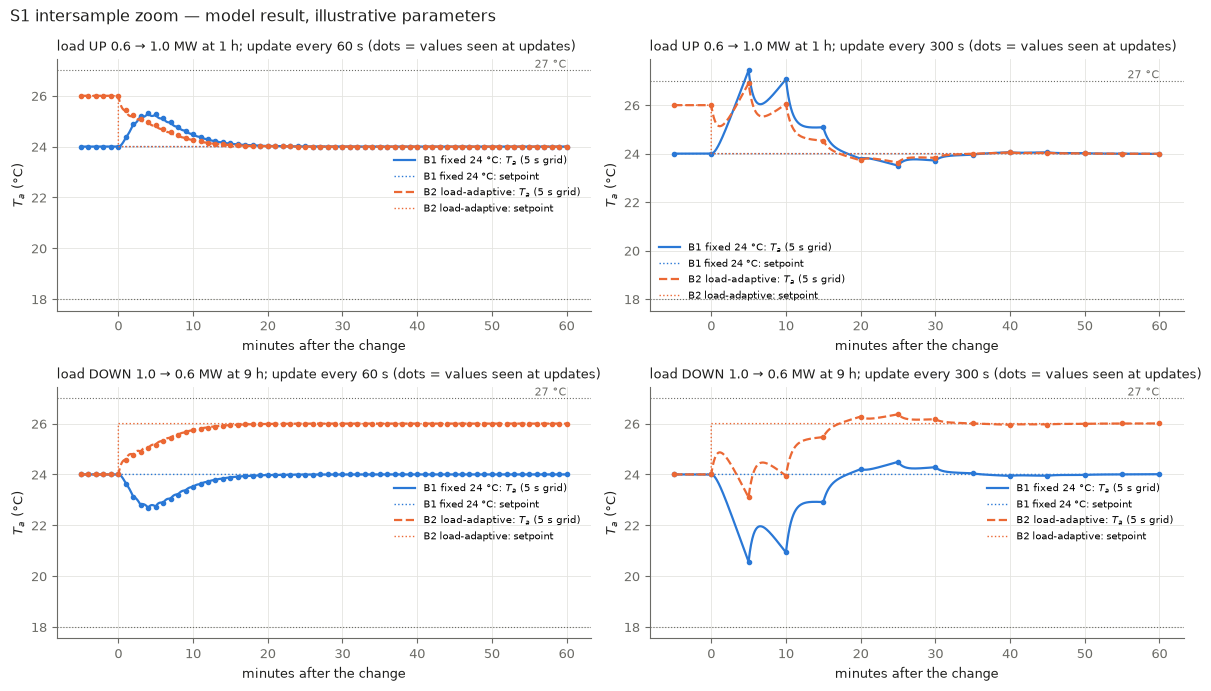

saved: fig06_b1_b2_S1.png fig07_b1_b2_S2c.png fig08_b1_b2_S1_zoom.png


In [9]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1d", "#6b6b66", "#e4e4e0"
plt.rcParams.update({"font.size": 9.5, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})
SER = (("B1", BLUE, "-", "B1 fixed 24 °C"), ("B2", ORANGE, "--", "B2 load-adaptive"))


def style(ax):
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)


def hline(ax, y, txt, x):
    ax.axhline(y, color=MUTED, lw=0.8, ls=":")
    if txt:
        ax.text(x, y, " " + txt, color=MUTED, fontsize=8, va="bottom", ha="right")


def comparison_figure(sid, fname, title):
    fig, axs = plt.subplots(5, 2, figsize=(12, 13), sharex=True)
    for j, dt in enumerate((60, 300)):
        for kind, col, ls, lab in SER:
            r = R[(sid, dt, kind)]
            th = r.t / H
            axs[0, j].plot(th, r.X[:, 1], color=col, ls=ls, lw=1.6, label=f"{lab}: $T_a$")
            axs[0, j].step(th, r.SP, where="post", color=col, ls=":", lw=1.0, label=f"{lab}: setpoint")
            axs[1, j].plot(th, r.X[:, 0], color=col, ls=ls, lw=1.6, label=lab)
            axs[2, j].step(th, r.Q / 1e6, where="post", color=col, ls=ls, lw=1.4, label=lab)
            axs[3, j].step(th, r.P_cool / 1e3, where="post", color=col, ls=ls, lw=1.4, label=lab)
            axs[4, j].plot(th, tm.J_to_kWh(r.E_cool), color=col, ls=ls, lw=1.6,
                           label=f"{lab}: {tm.J_to_kWh(r.E_cool[-1]):.0f} kWh$_e$")
        hline(axs[0, j], 27.0, "27 °C", 17); hline(axs[0, j], 18.0, "18 °C", 17)
        hline(axs[1, j], 40.0, "illustrative 40 °C", 17)
        hline(axs[2, j], p.Q_max / 1e6, "$Q_{max}$", 17)
        axs[0, j].set_title(f"update every {dt} s (Stage 2 gains, not retuned)", loc="left", color=INK)
        axs[4, j].set_xlabel("time (h)")
        for ax in axs[:, j]:
            ax.set_xlim(0, 17); style(ax)
    axs[0, 0].set_ylabel("room air $T_a$ (°C)"); axs[1, 0].set_ylabel("equipment $T_s$ (°C)")
    axs[2, 0].set_ylabel("heat removed $Q_c$ (MW$_{th}$)"); axs[3, 0].set_ylabel("cooling electricity (kW$_e$)")
    axs[4, 0].set_ylabel("cumulative cooling\nelectricity (kWh$_e$)")
    for i, loc in enumerate(("lower left", "center right", "center right", "center right", "upper left")):
        for ax in axs[i]:
            ax.legend(frameon=False, fontsize=7.5, loc=loc)
    fig.suptitle(title + " — model result, illustrative parameters", x=0.01, ha="left", color=INK)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=150); plt.show()


comparison_figure("S1", "fig06_b1_b2_S1.png", "S1: load 0.6 → 1.0 MW at 1 h → 0.6 MW at 9 h ($T_{out}$ 30 °C)")
comparison_figure("S2c", "fig07_b1_b2_S2c.png", "S2c (comparison variant): load 0.8 MW, $T_{out}$ 30 → 35 °C at 1 h → 30 °C at 9 h")

# zoom on the upward and downward load changes in S1 (intersample)
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
for i, (t0, lab) in enumerate(((1 * H, "load UP 0.6 → 1.0 MW at 1 h"), (9 * H, "load DOWN 1.0 → 0.6 MW at 9 h"))):
    for j, dt in enumerate((60, 300)):
        ax = axs[i, j]
        for kind, col, ls, l in SER:
            r = R[("S1", dt, kind)]
            z = (r.t >= t0 - 300) & (r.t <= t0 + 3600)
            ax.plot((r.t[z] - t0) / 60, r.X[z, 1], color=col, ls=ls, lw=1.6, label=f"{l}: $T_a$ (5 s grid)")
            ax.step((r.t[z] - t0) / 60, r.SP[z], where="post", color=col, ls=":", lw=1.0, label=f"{l}: setpoint")
            lz = (r.log["t"] >= t0 - 300) & (r.log["t"] <= t0 + 3600)
            ax.plot((r.log["t"][lz] - t0) / 60, r.log["T_a"][lz], ls="none", marker="o", ms=3, color=col)
        hline(ax, 27.0, "27 °C", 60); hline(ax, 18.0, "", 60)
        ax.set_title(f"{lab}; update every {dt} s (dots = values seen at updates)", loc="left", color=INK, fontsize=9)
        ax.set_xlabel("minutes after the change"); ax.set_ylabel("$T_a$ (°C)"); style(ax)
        ax.legend(frameon=False, fontsize=7.5, loc="best")
fig.suptitle("S1 intersample zoom — model result, illustrative parameters", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig08_b1_b2_S1_zoom.png", dpi=150); plt.show()
print("saved:", *sorted(x.name for x in FIG_DIR.glob("fig0[6-8]*.png")))

### Interpretation
<div style="background:#fdf6e3;border-left:6px solid #c98500;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>What the comparison shows (model behaviour, illustrative parameters)</b><br>
<ol>
<li><b>The prediction made before simulation matches the measured result.</b>
<ul>
<li>The quasi-steady COP estimate predicted +3.62 % (S1) and +8.15 % (S2c).</li>
<li>The eligible measured savings are +3.64 % (S1, 60 s) and +8.15 % (S2c, both intervals).</li>
<li>So almost all of the difference is the steady-state effect of running the air 2 K warmer while the load is below 1 MW. COP at 26 °C is 8.3 % better than at 24 °C ($T_{out}$ 30 °C), and 7.1 % better at 35 °C. Slightly less heat is also removed (in S2c, 13 816 vs 13 884 kWh$_{th}$), because a warmer room gains less heat through the envelope.</li>
<li>Transients add only about 0.02 percentage points.</li>
</ul></li>
<li><b>Why S1 saves less than S2c.</b> In S1, B2 differs from B1 only during the 9 h at 0.6 MW. At 1.0 MW both use 24 °C. In S2c the load stays at 0.8 MW, so B2 runs 2 K warmer for the whole 17 h.</li>
<li><b>Eligibility.</b>
<ul>
<li>S1 at 300 s is <b>not</b> eligible. B1 itself exceeds 27 °C after the load increase (27.44 °C, as in Stage 2), so no saving is claimed there.</li>
<li>B2 stayed within limits in that run, but only just: its maximum was 26.90 °C, 0.10 K below the limit.</li>
<li>All eligible comparisons pass the terminal checks: |ΔT| ≈ 10⁻⁹ K and ΔU ≈ 0.03–0.05 J.</li>
</ul></li>
<li><b>The saving is bought with thermal margin, not created for free.</b>
<ul>
<li>At 0.8 MW, B2 keeps the lumped equipment at 38 °C against B1's 36 °C, so 2 K less headroom to the illustrative 40 °C limit.</li>
<li>In the artificial S5 restart, B2 overshoots further above 27 °C than B1: 28.06 vs 26.07 °C at 60 s, and 31.81 vs 29.49 °C at 300 s.</li>
<li>The 1 K margin is provisional. Whether it is enough is an engineering question this model cannot answer.</li>
</ul></li>
<li><b>Confound: B2 also measures load.</b>
<ul>
<li>At a load step, B2's setpoint changes at the same update. That acts like an immediate load feedforward, which shapes B2's transients; its air stays within 24–26 °C through the 60 s S1 steps.</li>
<li>This affects transients, not the steady-state energy, which the prediction already explains.</li>
</ul></li>
<li><b>Failure tests (not rankings).</b>
<ul>
<li>In S3 (1.7 MW), B2's setpoint is clipped to 18 °C, so it pushes cooling to maximum sooner. Both controllers still exceed the limits.</li>
<li>In S4 (2.0 MW), both runs leave the COP domain and are stopped.</li>
</ul></li>
<li><b>A metric bug was found and fixed.</b> The settling metric first judged the last point of a window against the <i>next</i> window's setpoint, so B2 was wrongly reported as "not settled". Check M now guards this. Notebook 02's output is unchanged by the fix.</li>
</ol>
<b>Not shown here, all of which could change the conclusion.</b>
<ul>
<li>Servers drawing more power when warmer ($\kappa>0$). Spec Prop. 4 estimates that above about 0.7 %/K this would cancel the benefit; κ = 0 here.</li>
<li>Errors in the parameters or in the load measurement.</li>
<li>Real chiller curves and fan power.</li>
<li>Any real facility.</li>
</ul>

</div>

## 10. Summary (copyable)

In [10]:
groups = [
    ("B2 setpoint rule at 0.6 / 1.0 / 1.7 / 0.8 MW", r"SP\d"),
    ("Stored Stage 2 gains reproduced; poles inside unit circle", r"G[01]"),
    ("B2 equilibrium + no-disturbance stability", r"EQ"),
    ("solve_ivp replay (all comparison runs)", r"R"),
    ("Thermal energy balance; heat removed = sum(Q h)", r"E"),
    ("Grid refinement: extrema and Simpson E_cool", r"G"),
    ("Independent electricity quadrature", r"Q"),
    ("Anti-windup invariant (B2, all runs)", r"AW"),
    ("COP-domain stop logged (B2, S4)", r"COP"),
    ("Terminal state and dU (all comparison runs)", r"T"),
    ("Settling metric uses in-force setpoint at window end (regression)", r"M"),
]
lines = ["STAGE 3 (B2 vs B1) VERIFICATION SUMMARY (fresh kernel)", "-" * 72]
used = set()
for name, pat in groups:
    rows = [r for r in results if re.fullmatch(pat + r"(-.*)?", r[0])]
    used |= {r[0] for r in rows}
    n_ok = sum(r[4] for r in rows)
    lines.append(f"{'PASS' if rows and n_ok == len(rows) else 'FAIL'}  {name:58s} {n_ok:2d}/{len(rows):2d}")
assert used == {r[0] for r in results}, f"ungrouped: {set(r[0] for r in results) - used}"
lines += ["-" * 72, f"TOTAL {sum(r[4] for r in results)}/{len(results)} checks passed", ""]
lines += [f"PREDICTION (quasi-steady, before simulation): S1 {100*PRED['S1'][2]:+.2f} %, S2c {100*PRED['S2c'][2]:+.2f} %", ""]
lines += TAB + [""] + CTXT + [""] + FTXT
lines += [""] + [f"FINDING {fid}: {txt}" for fid, txt in findings]
print("\n".join(lines))

STAGE 3 (B2 vs B1) VERIFICATION SUMMARY (fresh kernel)
------------------------------------------------------------------------
PASS  B2 setpoint rule at 0.6 / 1.0 / 1.7 / 0.8 MW                4/ 4
PASS  Stored Stage 2 gains reproduced; poles inside unit circle   4/ 4
PASS  B2 equilibrium + no-disturbance stability                   2/ 2
PASS  solve_ivp replay (all comparison runs)                      8/ 8
PASS  Thermal energy balance; heat removed = sum(Q h)             8/ 8
PASS  Grid refinement: extrema and Simpson E_cool                 4/ 4
PASS  Independent electricity quadrature                          8/ 8
PASS  Anti-windup invariant (B2, all runs)                        2/ 2
PASS  COP-domain stop logged (B2, S4)                             2/ 2
PASS  Terminal state and dU (all comparison runs)                 8/ 8
PASS  Settling metric uses in-force setpoint at window end (regression)  2/ 2
------------------------------------------------------------------------
TOTAL 52/52